In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Task 1

In [6]:
df = pd.read_csv('Used_Cars_Homework.csv')
df.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [8]:
print(df.shape)
df.info()
df.isna().sum()

(300, 9)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age_years         300 non-null    int64  
 1   mileage_km        283 non-null    float64
 2   engine_l          284 non-null    float64
 3   power_hp          300 non-null    int64  
 4   brand             300 non-null    str    
 5   fuel_type         287 non-null    str    
 6   transmission      290 non-null    str    
 7   accident_history  300 non-null    str    
 8   price_azn         300 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 16.5 KB


age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [9]:
df.describe()

print(df['price_azn'].min())
print(df['price_azn'].max())
print(df['price_azn'].mean())


3805
51396
27806.573333333334


In [ ]:
# Task 2

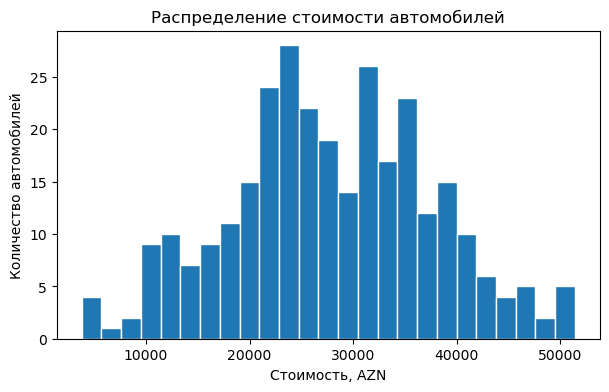

In [14]:
plt.figure(figsize=(7, 4))
plt.hist(df['price_azn'], bins=25,edgecolor='white')
plt.title('Распределение стоимости автомобилей')
plt.xlabel('Стоимость, AZN')
plt.ylabel('Количество автомобилей')
plt.show()

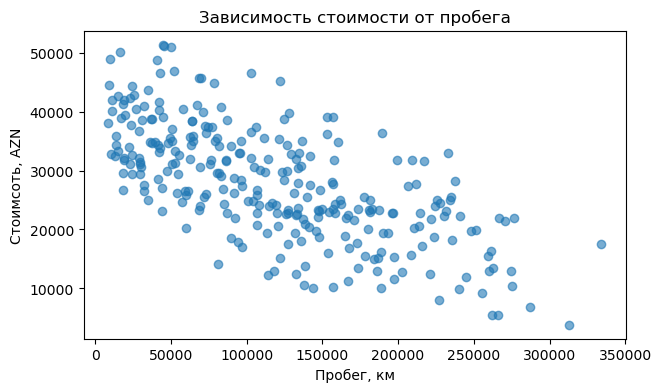

In [16]:
plt.figure(figsize=(7, 4))
plt.scatter(df['mileage_km'], df['price_azn'], alpha=0.6)
plt.title('Зависимость стоимости от пробега')
plt.xlabel('Пробег, км')
plt.ylabel('Стоимсоть, AZN')
plt.show()

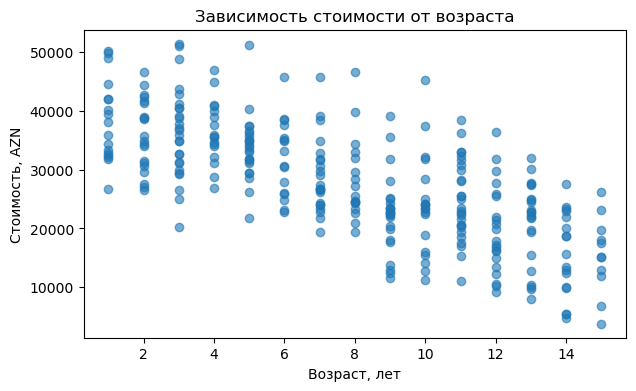

In [17]:
plt.figure(figsize=(7, 4))
plt.scatter(df['age_years'], df['price_azn'], alpha=0.6)
plt.title('Зависимость стоимости от возраста')
plt.xlabel('Возраст, лет')
plt.ylabel('Стоимость, AZN')
plt.show()

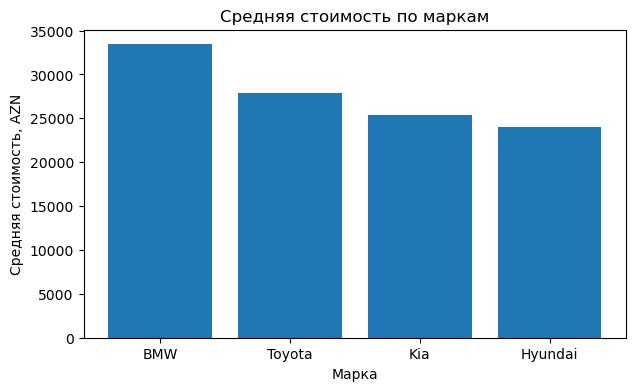

In [18]:
brand_mean = df.groupby('brand')['price_azn'].mean().sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(brand_mean.index, brand_mean.values)
plt.title('Средняя стоимость по маркам')
plt.xlabel('Марка')
plt.ylabel('Средняя стоимость, AZN')
plt.show()

In [20]:
# Task 3

In [22]:
df['mileage_per_year'] = df['mileage_km'] / df['age_years']

X = df.drop(columns='price_azn')
y = df['price_azn']

numeric_features = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
categorical_features = ['brand', 'fuel_type', 'transmission', 'accident_history']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
demo = X_train.copy()

codes, uniques = pd.factorize(demo['brand'])
demo['brand_factorize'] = codes
print(dict(zip(uniques, range(len(uniques)))))

ohe_demo = OneHotEncoder(sparse_output=False)
ohe_arr = ohe_demo.fit_transform(demo[['brand']])
ohe_df = pd.DataFrame(ohe_arr, columns=ohe_demo.get_feature_names_out(['brand']), index=demo.index).astype(int)

pd.concat([demo[['brand', 'brand_factorize']], ohe_df], axis=1).head(8)

{'BMW': 0, 'Toyota': 1, 'Kia': 2, 'Hyundai': 3}


,brand,brand_factorize,brand_BMW,brand_Hyundai,brand_Kia,brand_Toyota
232,BMW,0,1,0,0,0
59,Toyota,1,0,0,0,1
6,Toyota,1,0,0,0,1
185,BMW,0,1,0,0,0
173,Toyota,1,0,0,0,1
30,BMW,0,1,0,0,0
22,Toyota,1,0,0,0,1
256,Toyota,1,0,0,0,1


In [27]:
mileage = demo[['mileage_km']].fillna(demo['mileage_km'].median())

mm = MinMaxScaler().fit(mileage)
ss = StandardScaler().fit(mileage)

scaled = pd.DataFrame({
    'mileage_km': mileage['mileage_km'],
    'MinMaxScaler': mm.transform(mileage).ravel(),
    'StandardScaler': ss.transform(mileage).ravel()
})
scaled.head(8)

,mileage_km,MinMaxScaler,StandardScaler
232,52670.0,0.135150,-0.928737
59,81580.0,0.223927,-0.522960
6,124854.0,0.356814,0.084429
185,115668.0,0.328605,-0.044505
173,15054.0,0.019638,-1.456711
30,276575.0,0.822722,2.213966
22,193325.0,0.567076,1.045479
256,120461.0,0.343324,0.022769


In [28]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [29]:
# Task 3

In [32]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)
print('R2:', r2)

results = pd.DataFrame({
    'Реальная цена': y_test.values,
    'Прогноз': y_pred.round(0)
}, index=y_test.index)
results['Абсолютная ошибка'] = (results['Реальная цена'] - results['Прогноз']).abs()
results.head(10)

MAE: 1414.6217946851687
MSE: 2886404.319850028
RMSE: 1698.9421178633568
R2: 0.9717678175713534


,Реальная цена,Прогноз,Абсолютная ошибка
203,34837,32095.0,2742.0
266,34946,33158.0,1788.0
152,32214,31153.0,1061.0
9,36190,35781.0,409.0
233,25000,23648.0,1352.0
226,26522,27360.0,838.0
196,22711,24211.0,1500.0
109,33061,32078.0,983.0
5,18479,19694.0,1215.0
175,25003,23457.0,1546.0
